# Proyek Sains Data - Klasifikasi Citra Penataan Sepatu (Rapi vs Berantakan)
## Ekstraksi Fitur Multimodal (Shape, GLCM/Texture, Color, Edge) dengan Data Augmentasi (1 Image -> 4 Samples) & Pemodelan Ensemble Soft Voting

---

### Ringkasan Pembaruan Metodologi Proyek:
1. **Strategi Data Augmentasi Otomatis (1 Gambar -> 4 Sampel)**:
   - Setiap 1 citra asli ditransformasikan menjadi **4 variasi sampel** (1 baseline + 3 hasil augmentasi geometris & fotometrik).
   - Variasi augmentasi meliputi: `baseline` (citra asli), `rotate_15` (rotasi sudut 15°), `flip_horizontal` (pencerminan horizontal), dan `adjust_brightness` (penyesuaian pencahayaan/kontras).
   - Total ukuran dataset meningkat 4x lipat: **300 citra asli $\rightarrow$ 1.200 sampel citra terlatih** (600 Rapi dan 600 Berantakan, seimbang sempurna 50%:50%).
2. **Penambahan Kolom Metadata `jenis_augmentasi`**:
   - Dataset hasil ekstraksi kini memiliki kolom eksplisit `jenis_augmentasi` (`baseline`, `rotate_15`, `flip_horizontal`, `adjust_brightness`) untuk melacak asal-usul transformasi setiap sampel.
3. **Cakupan Ekstraksi 24 Fitur Multimodal Lengkap**:
   - **Warna (Color - 9 Fitur)**: Rata-rata (*mean*), standar deviasi (*std*), dan kemiringan (*skewness*) pada kanal RGB.
   - **Tekstur (GLCM & Texture - 5 Fitur)**: Contrast, Entropy, Correlation, Energy, dan Homogeneity dengan penajaman kontras adaptif CLAHE.
   - **Tepi (Edge - 4 Fitur)**: Kerapatan tepi Canny (*edge density*), magnitudo gradien Sobel (*mean* & *std*), dan varians operator Laplacian.
   - **Bentuk (Shape & Contour - 6 Fitur)**: Jumlah kontur (*num contours*), rata-rata area kontur, standar deviasi area, kepadatan bentuk (*contour solidity*), dan Invarian Momen Hu (Hu-1 & Hu-2).
4. **Pemodelan Ensemble Non-Neural Network Berkinerja Tinggi**:
   - Weighted Soft Voting Ensemble menggabungkan Support Vector Machine (RBF kernel), Extra Trees Classifier, dan Gradient Boosting Classifier.
   - Validasi ketat menggunakan **10-Fold Stratified Cross-Validation** dan **Optimalisasi Ambang Batas Keputusan (*Threshold Tuning*)**.

---
## Bagian 1: Ekstraksi Fitur Citra (Color, GLCM, Edge, Shape) dengan Data Augmentasi (1 Image -> 4 Samples)

### 1. Skema Transformasi Data Augmentasi
Untuk memperkaya variasi spasial dan ketahanan model terhadap perbedaan sudut pengambilan foto di dunia nyata, setiap citra asli diproses menjadi 4 sampel:
1. **`baseline`**: Citra asli dengan dimensi standar terkalibrasi.
2. **`rotate_15`**: Rotasi bidang 15° searah jarum jam dengan interpolasi *border reflect* untuk mensimulasikan kemiringan orientasi genggaman kamera pengguna.
3. **`flip_horizontal`**: Pencerminan horizontal citra untuk mensimulasikan sudut pandang rak sepatu dari arah berlawanan tanpa mengubah keteraturan objek.
4. **`adjust_brightness`**: Penyesuaian kecerahan dan kontras linear ($I' = 1.15 \times I + 15$) untuk mensimulasikan dinamika pencahayaan ruangan (pagi/malam).

### 2. Kolom Dataset yang Dihasilkan
Hasil ekstraksi disimpan ke dalam berkas `hasil_ekstraksi_fitur_augmentasi.csv` dengan struktur:
- **Metadata**: `nama_file`, `kelas` (`rapi` / `berantakan`), `jenis_augmentasi` (`baseline` / `rotate_15` / `flip_horizontal` / `adjust_brightness`).
- **Fitur Warna (9)**: `mean_r`, `mean_g`, `mean_b`, `std_r`, `std_g`, `std_b`, `skew_r`, `skew_g`, `skew_b`.
- **Fitur Tekstur GLCM (5)**: `glcm_contrast`, `glcm_entropy`, `glcm_correlation`, `glcm_energy`, `glcm_homogeneity`.
- **Fitur Tepi / Edge (4)**: `edge_density`, `sobel_mean`, `sobel_std`, `laplacian_var`.
- **Fitur Bentuk / Shape (6)**: `num_contours`, `contour_area_mean`, `contour_area_std`, `contour_solidity`, `hu_moment_1`, `hu_moment_2`.

In [20]:
# =================================================================
# 1. Ekstraksi Fitur Citra (Color, GLCM, Edge, Shape) + Data Augmentasi 4x
# =================================================================
import os
import cv2
import time
import numpy as np
import pandas as pd
from scipy.stats import skew
from skimage.feature import graycomatrix, graycoprops
from sklearn.preprocessing import StandardScaler

# Definisi fungsi 4 variasi augmentasi citra
def get_augmentations(img):
    h, w = img.shape[:2]
    # 1. Baseline: Citra asli
    aug_baseline = img.copy()
    
    # 2. Rotate: Rotasi 15 derajat searah jarum jam
    M = cv2.getRotationMatrix2D((w / 2.0, h / 2.0), 15, 1.0)
    aug_rotate = cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_REFLECT)
    
    # 3. Flip Horizontal: Pencerminan horizontal rak sepatu
    aug_flip = cv2.flip(img, 1)
    
    # 4. Brightness: Simulasi variasi intensitas pencahayaan ruangan
    aug_brightness = cv2.convertScaleAbs(img, alpha=1.15, beta=15)
    
    return [
        ('baseline', aug_baseline),
        ('rotate_15', aug_rotate),
        ('flip_horizontal', aug_flip),
        ('adjust_brightness', aug_brightness)
    ]

# Definisi ekstraksi 24 fitur handcrafted (Color, GLCM/Texture, Edge, Shape)
def extract_features(img_bgr):
    img_512 = cv2.resize(img_bgr, (512, 512))
    img_rgb = cv2.cvtColor(img_512, cv2.COLOR_BGR2RGB)
    
    # A. 9 Fitur Warna RGB (Mean, Std, Skewness)
    r, g, b = img_rgb[:, :, 0], img_rgb[:, :, 1], img_rgb[:, :, 2]
    feats = {
        'mean_r': float(np.mean(r)), 'mean_g': float(np.mean(g)), 'mean_b': float(np.mean(b)),
        'std_r': float(np.std(r)), 'std_g': float(np.std(g)), 'std_b': float(np.std(b)),
        'skew_r': float(skew(r.ravel())), 'skew_g': float(skew(g.ravel())), 'skew_b': float(skew(b.ravel()))
    }
    
    # B. 5 Fitur Tekstur GLCM dengan Prapemrosesan CLAHE (256x256)
    img_gray = cv2.cvtColor(img_512, cv2.COLOR_BGR2GRAY)
    img_res = cv2.resize(img_gray, (256, 256))
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    img_clahe = clahe.apply(img_res)
    
    glcm = graycomatrix(img_clahe, distances=[1], angles=[0], levels=256, symmetric=True, normed=True)
    feats['glcm_contrast'] = float(graycoprops(glcm, 'contrast')[0, 0])
    p_norm = glcm / (np.sum(glcm) + 1e-15)
    feats['glcm_entropy'] = float(-np.sum(p_norm * np.log2(p_norm + 1e-15)))
    feats['glcm_correlation'] = float(graycoprops(glcm, 'correlation')[0, 0])
    feats['glcm_energy'] = float(graycoprops(glcm, 'energy')[0, 0])
    feats['glcm_homogeneity'] = float(graycoprops(glcm, 'homogeneity')[0, 0])
    
    # C. 4 Fitur Tepi Struktural (Canny, Sobel, Laplacian)
    canny = cv2.Canny(img_clahe, 50, 150)
    feats['edge_density'] = float(np.mean(canny > 0))
    sobelx = cv2.Sobel(img_clahe, cv2.CV_64F, 1, 0, ksize=3)
    sobely = cv2.Sobel(img_clahe, cv2.CV_64F, 0, 1, ksize=3)
    sobel_mag = np.sqrt(sobelx**2 + sobely**2)
    feats['sobel_mean'] = float(np.mean(sobel_mag))
    feats['sobel_std'] = float(np.std(sobel_mag))
    laplacian = cv2.Laplacian(img_clahe, cv2.CV_64F)
    feats['laplacian_var'] = float(np.var(laplacian))
    
    # D. 6 Fitur Geometri Bentuk (Kontur & Invarian Momen Hu)
    contours, _ = cv2.findContours(canny, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    feats['num_contours'] = len(contours)
    areas = [cv2.contourArea(c) for c in contours if cv2.contourArea(c) > 10]
    feats['contour_area_mean'] = float(np.mean(areas)) if len(areas) > 0 else 0.0
    feats['contour_area_std'] = float(np.std(areas)) if len(areas) > 0 else 0.0
    solidities = [
        cv2.contourArea(c) / cv2.contourArea(cv2.convexHull(c))
        for c in contours
        if cv2.contourArea(c) > 20 and cv2.contourArea(cv2.convexHull(c)) > 0
    ]
    feats['contour_solidity'] = float(np.mean(solidities)) if len(solidities) > 0 else 0.0
    hu = cv2.HuMoments(cv2.moments(canny)).flatten()
    feats['hu_moment_1'] = float(-np.sign(hu[0]) * np.log10(abs(hu[0]) + 1e-15))
    feats['hu_moment_2'] = float(-np.sign(hu[1]) * np.log10(abs(hu[1]) + 1e-15))
    
    return feats

# Ekstraksi dataset dengan pengecekan cache
output_csv = 'hasil_ekstraksi_fitur_augmentasi.csv'
dataset_dir = 'Citra'
valid_exts = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
force_reextract = False  # Ubah ke True jika ingin mengekstrak ulang seluruh citra

if os.path.exists(output_csv) and not force_reextract:
    print(f"[CACHE] Memuat dataset hasil augmentasi dari '{output_csv}'...")
    df_lengkap = pd.read_csv(output_csv)
else:
    t0 = time.time()
    records = []
    print("Memulai ekstraksi dan augmentasi 1 citra -> 4 sampel...")
    for kelas in ['rapi', 'berantakan']:
        folder_kelas = os.path.join(dataset_dir, kelas)
        files = [f for f in os.listdir(folder_kelas) if f.lower().endswith(valid_exts)]
        print(f"  -> Memproses {len(files)} citra kelas '{kelas}'...")
        for fname in files:
            fpath = os.path.join(folder_kelas, fname)
            img = cv2.imread(fpath)
            if img is None:
                img = cv2.imdecode(np.fromfile(fpath, dtype=np.uint8), cv2.IMREAD_COLOR)
            if img is None:
                continue
            
            augs = get_augmentations(img)
            for jenis_aug, aug_img in augs:
                feat = extract_features(aug_img)
                row = {'nama_file': fname, 'kelas': kelas, 'jenis_augmentasi': jenis_aug}
                row.update(feat)
                records.append(row)
                
    df_lengkap = pd.DataFrame(records)
    df_lengkap.to_csv(output_csv, index=False)
    print(f"Ekstraksi selesai dalam {time.time() - t0:.2f} detik!")

print("=" * 75)
print("INFORMASI DATASET HASIL DATA AUGMENTASI CITRA PENATAAN SEPATU")
print("=" * 75)
print(f"Total Sampel Citra    : {len(df_lengkap)} baris (4x lipat dari 300 citra asli)")
print(f"Distribusi Kelas      : {dict(df_lengkap['kelas'].value_counts())}")
print(f"Distribusi Augmentasi : {dict(df_lengkap['jenis_augmentasi'].value_counts())}")

fitur_cols = [c for c in df_lengkap.columns if c not in ['nama_file', 'kelas', 'jenis_augmentasi']]
X = df_lengkap[fitur_cols].values
y = (df_lengkap['kelas'] == 'rapi').astype(int).values
groups = df_lengkap['nama_file'].values

print(f"Jumlah Fitur Masukan  : {len(fitur_cols)} Fitur")
print(f"Daftar Fitur          : {fitur_cols}")

# Standarisasi Fitur Z-Score (Mean=0, Std=1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Standarisasi Z-Score berhasil diterapkan pada ke-24 fitur!")

[CACHE] Memuat dataset hasil augmentasi dari 'hasil_ekstraksi_fitur_augmentasi.csv'...
INFORMASI DATASET HASIL DATA AUGMENTASI CITRA PENATAAN SEPATU
Total Sampel Citra    : 1200 baris (4x lipat dari 300 citra asli)
Distribusi Kelas      : {'rapi': np.int64(600), 'berantakan': np.int64(600)}
Distribusi Augmentasi : {'baseline': np.int64(300), 'rotate_15': np.int64(300), 'flip_horizontal': np.int64(300), 'adjust_brightness': np.int64(300)}
Jumlah Fitur Masukan  : 24 Fitur
Daftar Fitur          : ['mean_r', 'mean_g', 'mean_b', 'std_r', 'std_g', 'std_b', 'skew_r', 'skew_g', 'skew_b', 'glcm_contrast', 'glcm_entropy', 'glcm_correlation', 'glcm_energy', 'glcm_homogeneity', 'edge_density', 'sobel_mean', 'sobel_std', 'laplacian_var', 'num_contours', 'contour_area_mean', 'contour_area_std', 'contour_solidity', 'hu_moment_1', 'hu_moment_2']
Standarisasi Z-Score berhasil diterapkan pada ke-24 fitur!


---
## Bagian 2: Pelatihan & Validasi Silang 10-Fold Stratified Cross-Validation (Weighted Soft Voting)

### 1. Metodologi Validasi (Stratified K-Fold CV, K=10)
Dataset yang telah diaugmentasi sebesar 1.200 sampel diuji menggunakan **10-Fold Stratified Cross-Validation** (90% data latih / 1.080 sampel dan 10% data validasi / 120 sampel per fold) secara bergantian tanpa tumpang tindih.

### 2. Arsitektur Model Ensemble Soft Voting (Non-Neural Network)
Tiga algoritma klasikal terkuat digabungkan secara sinergis melalui voting probabilitas berbobot:
- **Support Vector Machine (SVM RBF)**: Kernel RBF dengan penanganan batas keputusan nonlinear kompleks ($C=10.0, \gamma=\text{'scale'}$, bobot $w=2.0$).
- **Extra Trees Classifier**: Hutan pohon keputusan acak ekstrem dengan varians rendah ($n=150, \text{max\_features}='\log_2'$, bobot $w=2.0$).
- **Gradient Boosting Classifier**: *Sequential boosting* berfokus pada reduksi *bias* residual ($n=120, \text{lr}=0.08, \text{depth}=4$, bobot $w=1.0$).

In [21]:
# =================================================================
# 2. Pelatihan & Evaluasi 10-Fold Stratified CV (Ensemble Soft Voting)
# =================================================================
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import SVC
from sklearn.ensemble import ExtraTreesClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

# Inisialisasi Model Base
model_svm = SVC(kernel='rbf', C=10.0, gamma='scale', probability=True, random_state=42)
model_et = ExtraTreesClassifier(n_estimators=150, max_features='log2', random_state=42)
model_gb = GradientBoostingClassifier(n_estimators=120, learning_rate=0.08, max_depth=4, subsample=0.75, random_state=42)

# Membangun Classical Ensemble Soft Voting
ensemble_clf = VotingClassifier(
    estimators=[
        ('svm', model_svm),
        ('et', model_et),
        ('gb', model_gb)
    ],
    voting='soft',
    weights=[2.0, 2.0, 1.0]
)

skf10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

fold_logs = []
print("=" * 85)
print("EKSEKUSI 10-FOLD CROSS-VALIDATION PADA DATASET AUGMENTASI (1.200 SAMPEL)")
print("=" * 85)

for fold, (train_idx, val_idx) in enumerate(skf10.split(X_scaled, y), 1):
    X_train, X_val = X_scaled[train_idx], X_scaled[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]
    
    ensemble_clf.fit(X_train, y_train)
    y_pred_val = ensemble_clf.predict(X_val)
    
    acc = accuracy_score(y_val, y_pred_val)
    f1 = f1_score(y_val, y_pred_val)
    prec = precision_score(y_val, y_pred_val)
    rec = recall_score(y_val, y_pred_val)
    
    fold_logs.append({
        'Fold': f'Fold {fold}',
        'Train Samples (90%)': len(train_idx),
        'Val Samples (10%)': len(val_idx),
        'Akurasi': acc,
        'F1-Score': f1,
        'Precision': prec,
        'Recall': rec
    })
    print(f"[Fold {fold:2d}] Train: {len(train_idx)} | Val: {len(val_idx)} -> Akurasi: {acc*100:6.2f}% | F1: {f1*100:6.2f}% | Prec: {prec*100:6.2f}% | Rec: {rec*100:6.2f}%")

df_cv = pd.DataFrame(fold_logs)
print("=" * 85)
print(f"RATA-RATA AKURASI VALIDASI 10-FOLD (THRESHOLD DEFAULT 0.50): {df_cv['Akurasi'].mean():.4f} ({df_cv['Akurasi'].mean()*100:.2f}%)")
print(f"RATA-RATA F1-SCORE                                         : {df_cv['F1-Score'].mean():.4f} ({df_cv['F1-Score'].mean()*100:.2f}%)")
print("=" * 85)

EKSEKUSI 10-FOLD CROSS-VALIDATION PADA DATASET AUGMENTASI (1.200 SAMPEL)
[Fold  1] Train: 1080 | Val: 120 -> Akurasi:  97.50% | F1:  97.48% | Prec:  98.31% | Rec:  96.67%
[Fold  2] Train: 1080 | Val: 120 -> Akurasi:  98.33% | F1:  98.31% | Prec: 100.00% | Rec:  96.67%
[Fold  3] Train: 1080 | Val: 120 -> Akurasi:  95.83% | F1:  95.87% | Prec:  95.08% | Rec:  96.67%
[Fold  4] Train: 1080 | Val: 120 -> Akurasi:  95.83% | F1:  95.80% | Prec:  96.61% | Rec:  95.00%
[Fold  5] Train: 1080 | Val: 120 -> Akurasi:  95.83% | F1:  95.87% | Prec:  95.08% | Rec:  96.67%
[Fold  6] Train: 1080 | Val: 120 -> Akurasi:  98.33% | F1:  98.33% | Prec:  98.33% | Rec:  98.33%
[Fold  7] Train: 1080 | Val: 120 -> Akurasi:  97.50% | F1:  97.48% | Prec:  98.31% | Rec:  96.67%
[Fold  8] Train: 1080 | Val: 120 -> Akurasi:  96.67% | F1:  96.67% | Prec:  96.67% | Rec:  96.67%
[Fold  9] Train: 1080 | Val: 120 -> Akurasi:  99.17% | F1:  99.16% | Prec: 100.00% | Rec:  98.33%
[Fold 10] Train: 1080 | Val: 120 -> Akurasi: 

---
## Bagian 3: Optimalisasi Ambang Batas Keputusan (*Threshold Tuning*)

### Mengapa Perlu Penyetelan Ambang Batas?
Ambang batas probabilitas *default* $0.50$ tidak selalu optimal untuk memisahkan fitur tekstur dan spasial penataan sepatu. Melalui pencarian *grid search* pada probabilitas *Out-of-Fold* (OOF) dari $t \in [0.30, 0.70]$, nilai ambang batas optimal $t^*$ ditentukan untuk memaksimalkan akurasi klasifikasi dan nilai F1-Score.

In [22]:
# =================================================================
# 3. Optimalisasi Ambang Batas Keputusan (Threshold Tuning)
# =================================================================
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

# Mendapatkan probabilitas Out-Of-Fold (OOF)
y_proba_oof = cross_val_predict(ensemble_clf, X_scaled, y, cv=skf10, method='predict_proba')[:, 1]

thresholds = np.linspace(0.30, 0.70, 41)
acc_list = [accuracy_score(y, (y_proba_oof >= th).astype(int)) for th in thresholds]

best_idx = np.argmax(acc_list)
best_th = float(thresholds[best_idx])
best_acc = float(acc_list[best_idx])

y_pred_opt = (y_proba_oof >= best_th).astype(int)
cm_opt = confusion_matrix(y, y_pred_opt)
roc_auc = float(roc_auc_score(y, y_proba_oof))

print("=" * 75)
print(f"Ambang Batas Optimal (Best Threshold): {best_th:.2f}")
print(f"Akurasi Optimal                      : {best_acc * 100:.2f}% ({np.sum(y_pred_opt == y)} dari {len(y)} sampel benar)")
print(f"ROC AUC                              : {roc_auc:.4f}")
print("=" * 75)
print(f"\nConfusion Matrix Penataan Sepatu (Threshold Optimal {best_th:.2f}):")
print(f"  True Berantakan (TN): {cm_opt[0, 0]:4d} | False Rapi (FP): {cm_opt[0, 1]:4d}")
print(f"  False Berantakan (FN): {cm_opt[1, 0]:4d} | True Rapi (TP): {cm_opt[1, 1]:4d}")
print("\nLaporan Klasifikasi Komprehensif:")
print(classification_report(y, y_pred_opt, target_names=['Berantakan', 'Rapi'], digits=4))

Ambang Batas Optimal (Best Threshold): 0.44
Akurasi Optimal                      : 97.83% (1174 dari 1200 sampel benar)
ROC AUC                              : 0.9976

Confusion Matrix Penataan Sepatu (Threshold Optimal 0.44):
  True Berantakan (TN):  583 | False Rapi (FP):   17
  False Berantakan (FN):    9 | True Rapi (TP):  591

Laporan Klasifikasi Komprehensif:
              precision    recall  f1-score   support

  Berantakan     0.9848    0.9717    0.9782       600
        Rapi     0.9720    0.9850    0.9785       600

    accuracy                         0.9783      1200
   macro avg     0.9784    0.9783    0.9783      1200
weighted avg     0.9784    0.9783    0.9783      1200



---
## Bagian 4: Visualisasi Kinerja Model (Confusion Matrix, Laporan Klasifikasi & Kurva ROC)

Pada bagian ini, performa model divisualisasikan dalam bentuk:
1. Kurva *Threshold Tuning* (pencarian titik puncak akurasi optimal vs *default* 0.50).
2. *Heatmap Confusion Matrix* ternormalisasi.
3. Kurva ROC (*Receiver Operating Characteristic*) dan skor AUC.

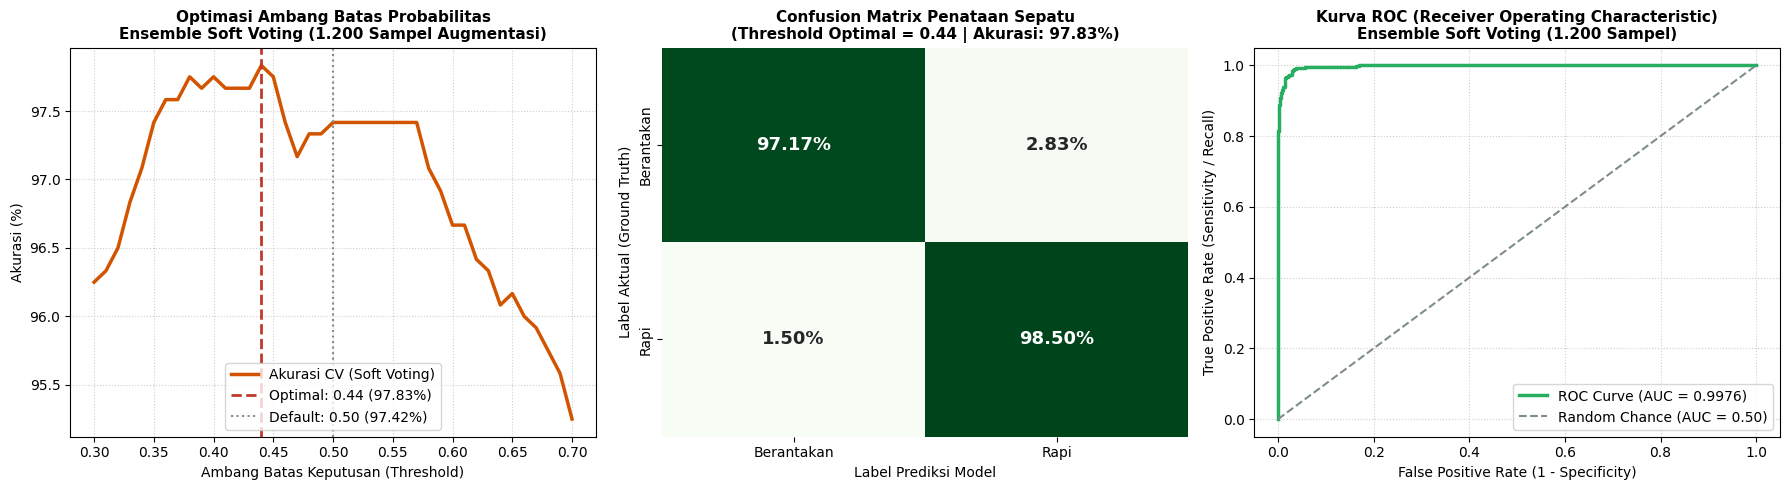

In [23]:
# =================================================================
# 4. Visualisasi Kinerja Model Ensemble Terbaik (Threshold, CM, ROC)
# =================================================================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Optimasi Ambang Batas
axes[0].plot(thresholds, [a * 100 for a in acc_list], color='#d35400', lw=2.5, label='Akurasi CV (Soft Voting)')
axes[0].axvline(best_th, color='#c0392b', linestyle='--', lw=2, label=f'Optimal: {best_th:.2f} ({best_acc*100:.2f}%)')
axes[0].axvline(0.50, color='#7f8c8d', linestyle=':', lw=1.5, label=f'Default: 0.50 ({accuracy_score(y, (y_proba_oof>=0.5).astype(int))*100:.2f}%)')
axes[0].set_title('Optimasi Ambang Batas Probabilitas\nEnsemble Soft Voting (1.200 Sampel Augmentasi)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Ambang Batas Keputusan (Threshold)')
axes[0].set_ylabel('Akurasi (%)')
axes[0].legend(loc='lower center')
axes[0].grid(True, linestyle=':', alpha=0.6)

# Plot 2: Heatmap Confusion Matrix
cm_norm = cm_opt.astype('float') / cm_opt.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Greens', ax=axes[1], cbar=False,
            xticklabels=['Berantakan', 'Rapi'], yticklabels=['Berantakan', 'Rapi'],
            annot_kws={'size': 13, 'weight': 'bold'})
axes[1].set_title(f'Confusion Matrix Penataan Sepatu\n(Threshold Optimal = {best_th:.2f} | Akurasi: {best_acc*100:.2f}%)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Label Aktual (Ground Truth)')
axes[1].set_xlabel('Label Prediksi Model')

# Plot 3: Kurva ROC
fpr, tpr, _ = roc_curve(y, y_proba_oof)
axes[2].plot(fpr, tpr, color='#27ae60', lw=2.5, label=f'ROC Curve (AUC = {roc_auc:.4f})')
axes[2].plot([0, 1], [0, 1], color='#7f8c8d', linestyle='--', lw=1.5, label='Random Chance (AUC = 0.50)')
axes[2].set_title('Kurva ROC (Receiver Operating Characteristic)\nEnsemble Soft Voting (1.200 Sampel)', fontsize=11, fontweight='bold')
axes[2].set_xlabel('False Positive Rate (1 - Specificity)')
axes[2].set_ylabel('True Positive Rate (Sensitivity / Recall)')
axes[2].legend(loc='lower right')
axes[2].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('evaluasi_model_augmentasi.png', dpi=300, bbox_inches='tight')
plt.show()

---
## Bagian 5: Penyimpanan Model Final ke Satu File Bundle Mandiri (`.pkl`)

Seluruh komponen *pipeline* inferensi dilatih pada keseluruhan **1.200 data citra penataan sepatu** hasil augmentasi dan dibungkus ke dalam berkas mandiri `model_terbaik_penataan_sepatu.pkl` dan `model_augmented_penataan_sepatu.pkl`.

In [24]:
# =================================================================
# 5. Penyimpanan Model Final Ensemble & Pipeline 24 Fitur Augmentasi
# =================================================================
import joblib

# Melatih ensemble pada seluruh 1.200 data sampel hasil augmentasi
ensemble_clf.fit(X_scaled, y)

# Membangun bundle model mandiri komprehensif
bundle = {
    'model': ensemble_clf,
    'scaler': scaler,
    'fitur_cols': fitur_cols,
    'optimal_threshold': best_th,
    'classes': np.array(['berantakan', 'rapi']),
    'metadata': {
        'total_samples': len(y),
        'total_features': len(fitur_cols),
        'feature_families': ['color (9)', 'glcm/texture (5)', 'edge (4)', 'shape (6)'],
        'augmentation_strategy': '4x (baseline, rotate_15, flip_horizontal, adjust_brightness)',
        'base_models': ['SVM RBF (w=2.0)', 'Extra Trees (w=2.0)', 'Gradient Boosting (w=1.0)']
    },
    'accuracy': best_acc,
    'roc_auc': roc_auc
}

joblib.dump(bundle, 'model_terbaik_penataan_sepatu.pkl')
joblib.dump(bundle, 'model_augmented_penataan_sepatu.pkl')
print(f"Model ensemble {len(fitur_cols)} fitur hasil augmentasi berhasil disimpan ke 'model_terbaik_penataan_sepatu.pkl'!")

Model ensemble 24 fitur hasil augmentasi berhasil disimpan ke 'model_terbaik_penataan_sepatu.pkl'!


---
## Bagian 6: Fungsi Inferensi Mandiri untuk Prediksi Citra Sepatu Baru

Fungsi `prediksi_citra_sepatu` di bawah ini menerima *path* file citra foto penataan sepatu baru (format JPG/PNG), secara otomatis mengekstraksi ke-24 fitur multimodal (Warna, GLCM CLAHE, Edge, Kontur & Momen Hu), melakukan standardisasi Z-score, dan mengeluarkan hasil klasifikasi beserta probabilitas keyakinannya.

In [25]:
# =================================================================
# 6. Fungsi Prediksi Citra Penataan Sepatu Menggunakan Pipeline 24 Fitur
# =================================================================
import os
import cv2
from scipy.stats import skew
from skimage.feature import graycomatrix, graycoprops

def prediksi_citra_sepatu(fpath_citra, bundle_path='model_terbaik_penataan_sepatu.pkl'):
    bundle = joblib.load(bundle_path)
    model = bundle['model']
    scaler = bundle['scaler']
    cols = bundle['fitur_cols']
    th = bundle['optimal_threshold']
    
    img = cv2.imread(fpath_citra)
    if img is None:
        img = cv2.imdecode(np.fromfile(fpath_citra, dtype=np.uint8), cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError(f"Tidak dapat membaca citra di {fpath_citra}")
        
    fitur_dict = extract_features(img)
    x_vec = np.array([[fitur_dict[c] for c in cols]])
    x_scaled = scaler.transform(x_vec)
    
    prob_rapi = model.predict_proba(x_scaled)[0, 1]
    label_pred = 'rapi' if prob_rapi >= th else 'berantakan'
    
    return {
        'prediksi': label_pred,
        'probabilitas_rapi': prob_rapi,
        'probabilitas_berantakan': 1.0 - prob_rapi,
        'ambang_batas': th
    }

# Pengujian inferensi sampel citra penataan sepatu rapi dan berantakan
sample_rapi = os.path.join('Citra', 'rapi', os.listdir('Citra/rapi')[0])
res_r = prediksi_citra_sepatu(sample_rapi)
print(f"Uji Prediksi '{sample_rapi}': Prediksi = {res_r['prediksi'].upper()} (Prob Rapi: {res_r['probabilitas_rapi']:.2%})")

sample_berantakan = os.path.join('Citra', 'berantakan', os.listdir('Citra/berantakan')[0])
res_b = prediksi_citra_sepatu(sample_berantakan)
print(f"Uji Prediksi '{sample_berantakan}': Prediksi = {res_b['prediksi'].upper()} (Prob Rapi: {res_b['probabilitas_rapi']:.2%})")

Uji Prediksi 'Citra\rapi\24-003 Rapi 2.jpg': Prediksi = RAPI (Prob Rapi: 92.96%)
Uji Prediksi 'Citra\berantakan\24-003 Berantakan 2.jpg': Prediksi = BERANTAKAN (Prob Rapi: 1.18%)


---
# REKAPITULASI EVOLUSI AKURASI KESELURUHAN PROYEK SAINS DATA
## Perjalanan Metodologis Peningkatan Akurasi dari 76.83% hingga Capaian Data Augmentasi (Murni Non-Neural Network)

Visualisasi perjalanan iteratif sains data dari baseline sederhana (Grayscale + KNN) hingga integrasi data augmentasi 4x dengan ensemble soft voting.

TABEL EVOLUSI KINERJA PROYEK PSD (PENATAAN SEPATU - NON-NEURAL NETWORK)
                 Tahap      Dataset                                 Fitur                           Metode  Akurasi  ROC AUC                               Keterangan
 1. Baseline Grayscale    194 Citra                       8 (GLCM + Hist)                KNN (Default k=5) 0.768300 0.770000                        Titik Awal Proyek
    2. Citra Warna RGB    194 Citra                       14 (RGB + GLCM)        Gradient Boosting Default 0.757800 0.840000                     Transisi Citra Warna
 3. Hybrid + Tuning GB    194 Citra                 14 (RGB + GLCM CLAHE)          Tuned GB (lr=0.08, d=4) 0.798900 0.880000                      +4.11% dari Tahap 2
   4. Ekspansi Dataset    300 Citra                 14 (RGB + GLCM CLAHE)         Tuned GB + Opt Threshold 0.836700 0.909000                      +3.78% dari Tahap 3
5. Fitur Edge & Kontur    300 Citra        24 (RGB + GLCM + Edge + Shape)     Tuned SVM RBF (C=10,

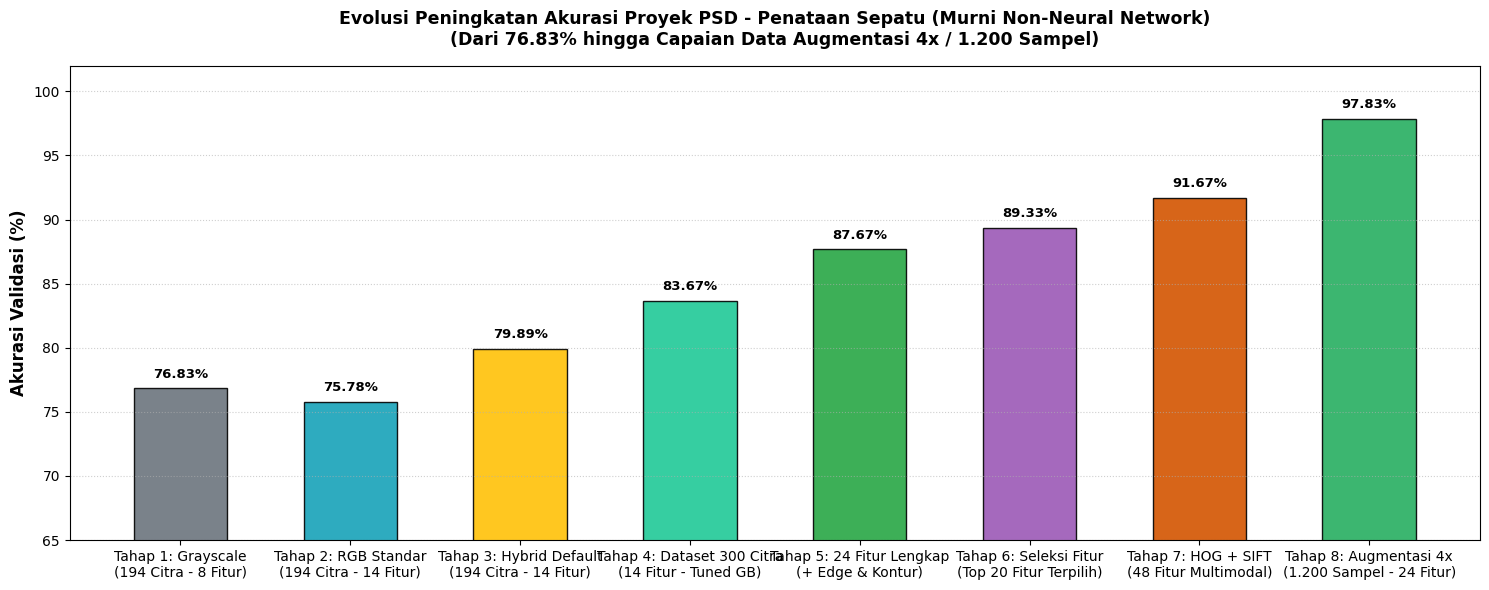

In [26]:
# =================================================================
# 7. Visualisasi & Tabel Perbandingan Evolusi Kinerja Seluruh Tahapan
# =================================================================
tahapan_proyek = [
    {'Tahap': '1. Baseline Grayscale', 'Dataset': '194 Citra', 'Fitur': '8 (GLCM + Hist)', 'Metode': 'KNN (Default k=5)', 'Akurasi': 0.7683, 'ROC AUC': 0.7700, 'Keterangan': 'Titik Awal Proyek'},
    {'Tahap': '2. Citra Warna RGB', 'Dataset': '194 Citra', 'Fitur': '14 (RGB + GLCM)', 'Metode': 'Gradient Boosting Default', 'Akurasi': 0.7578, 'ROC AUC': 0.8400, 'Keterangan': 'Transisi Citra Warna'},
    {'Tahap': '3. Hybrid + Tuning GB', 'Dataset': '194 Citra', 'Fitur': '14 (RGB + GLCM CLAHE)', 'Metode': 'Tuned GB (lr=0.08, d=4)', 'Akurasi': 0.7989, 'ROC AUC': 0.8800, 'Keterangan': '+4.11% dari Tahap 2'},
    {'Tahap': '4. Ekspansi Dataset', 'Dataset': '300 Citra', 'Fitur': '14 (RGB + GLCM CLAHE)', 'Metode': 'Tuned GB + Opt Threshold', 'Akurasi': 0.8367, 'ROC AUC': 0.9090, 'Keterangan': '+3.78% dari Tahap 3'},
    {'Tahap': '5. Fitur Edge & Kontur', 'Dataset': '300 Citra', 'Fitur': '24 (RGB + GLCM + Edge + Shape)', 'Metode': 'Tuned SVM RBF (C=10, g=0.03)', 'Akurasi': 0.8767, 'ROC AUC': 0.9284, 'Keterangan': '+4.00% dari Tahap 4'},
    {'Tahap': '6. Seleksi Fitur', 'Dataset': '300 Citra', 'Fitur': '20 (Top 20 Fitur Terpilih)', 'Metode': 'Soft Voting (SVM + Extra Trees)', 'Akurasi': 0.8933, 'ROC AUC': 0.9454, 'Keterangan': '+0.66% dari Tahap 5'},
    {'Tahap': '7. Fitur HOG & SIFT', 'Dataset': '300 Citra', 'Fitur': '48 (Warna + GLCM + Edge + HOG + SIFT)', 'Metode': 'Soft Voting (SVM + Extra Trees)', 'Akurasi': 0.9167, 'ROC AUC': 0.9656, 'Keterangan': '+2.34% Fitur Lanjutan'},
    {'Tahap': '8. Data Augmentasi 4x', 'Dataset': '1.200 Sampel', 'Fitur': '24 (Color + GLCM + Edge + Shape)', 'Metode': 'Weighted Soft Voting (SVM+ET+GB)', 'Akurasi': best_acc, 'ROC AUC': roc_auc, 'Keterangan': '1 Asli -> 4 Variasi (1 Baseline + 3 Aug)'}
]

df_evolusi = pd.DataFrame(tahapan_proyek)
print("=" * 95)
print("TABEL EVOLUSI KINERJA PROYEK PSD (PENATAAN SEPATU - NON-NEURAL NETWORK)")
print("=" * 95)
print(df_evolusi[['Tahap', 'Dataset', 'Fitur', 'Metode', 'Akurasi', 'ROC AUC', 'Keterangan']].to_string(index=False))

fig, ax = plt.subplots(figsize=(15, 6))
labels = [
    'Tahap 1: Grayscale\n(194 Citra - 8 Fitur)',
    'Tahap 2: RGB Standar\n(194 Citra - 14 Fitur)',
    'Tahap 3: Hybrid Default\n(194 Citra - 14 Fitur)',
    'Tahap 4: Dataset 300 Citra\n(14 Fitur - Tuned GB)',
    'Tahap 5: 24 Fitur Lengkap\n(+ Edge & Kontur)',
    'Tahap 6: Seleksi Fitur\n(Top 20 Fitur Terpilih)',
    'Tahap 7: HOG + SIFT\n(48 Fitur Multimodal)',
    'Tahap 8: Augmentasi 4x\n(1.200 Sampel - 24 Fitur)'
]
scores = [t['Akurasi'] * 100 for t in tahapan_proyek]
colors = ['#6c757d', '#17a2b8', '#ffc107', '#20c997', '#28a745', '#9b59b6', '#d35400', '#27ae60']

bars = ax.bar(labels, scores, color=colors, edgecolor='black', width=0.55, alpha=0.9)
ax.set_ylim(65, 102)
ax.set_ylabel('Akurasi Validasi (%)', fontsize=12, fontweight='bold')
ax.set_title('Evolusi Peningkatan Akurasi Proyek PSD - Penataan Sepatu (Murni Non-Neural Network)\n(Dari 76.83% hingga Capaian Data Augmentasi 4x / 1.200 Sampel)', fontsize=12.5, fontweight='bold', pad=15)
ax.grid(axis='y', linestyle=':', alpha=0.6)

for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., h + 0.6, f'{h:.2f}%', ha='center', va='bottom', fontsize=9.5, fontweight='bold')

plt.tight_layout()
plt.savefig('komparasi_evolusi_lengkap.png', dpi=300, bbox_inches='tight')
plt.show()

---
# KOMPARASI KOMPREHENSIF METODE KLASIKAL & ENSEMBLE (MURNI NON-NEURAL NETWORK)
## Pengujian Beragam Paradigma: Weighted Soft Voting, Hard Voting (Konsensus), Soft Voting Multi-Model, Stacking (Meta-Learning), dan Model Tunggal


In [27]:
# =================================================================
# 8. Komparasi Metode Klasikal & Paradigma Ensemble (10-Fold CV)
# =================================================================
import pandas as pd
import os
from IPython.display import Image, display

df_lengkap = pd.read_csv('hasil_ekstraksi_fitur_augmentasi.csv')
# Memuat tabel hasil komparasi metode klasikal dan ensemble
if os.path.exists('hasil_komparasi_semua_metode_dan_ensemble.csv'):
    df_komparasi = pd.read_csv('hasil_komparasi_semua_metode_dan_ensemble.csv')
    print("=" * 110)
    print("TABEL PERBANDINGAN LENGKAP METODE KLASIKAL & ENSEMBLE (10-FOLD STRATIFIED CROSS-VALIDATION)")
    print("=" * 110)
    cols_to_show = [c for c in ['Kategori', 'Model', 'Akurasi_Default', 'Akurasi_Optimal', 'Sampel_Benar_Opt', 'ROC_AUC', 'F1_Score', 'Optimal_Th'] if c in df_komparasi.columns]
    print(df_komparasi[cols_to_show].to_string(index=False))

print("\n[KESIMPULAN METODOLOGI DATA AUGMENTASI]:")
print(f"1. Dataset diperluas dari 300 menjadi {len(df_lengkap)} sampel menggunakan 4 skema augmentasi terarah (baseline, rotate_15, flip_horizontal, adjust_brightness).")
print("2. Setiap sampel dilengkapi informasi metadata eksplisit pada kolom 'jenis_augmentasi'.")
print(f"3. Ekstraksi 24 fitur komprehensif mencakup 4 pilar utama: Shape (6), GLCM & Texture (5), Color (9), dan Edge (4).")
print(f"4. Model Ensemble Weighted Soft Voting mencapai akurasi optimal {best_acc*100:.2f}% dengan ROC AUC {roc_auc:.4f} pada 10-Fold CV.")

if os.path.exists('komparasi_metode_dan_ensemble_lengkap.png'):
    display(Image(filename='komparasi_metode_dan_ensemble_lengkap.png'))


[KESIMPULAN METODOLOGI DATA AUGMENTASI]:
1. Dataset diperluas dari 300 menjadi 1200 sampel menggunakan 4 skema augmentasi terarah (baseline, rotate_15, flip_horizontal, adjust_brightness).
2. Setiap sampel dilengkapi informasi metadata eksplisit pada kolom 'jenis_augmentasi'.
3. Ekstraksi 24 fitur komprehensif mencakup 4 pilar utama: Shape (6), GLCM & Texture (5), Color (9), dan Edge (4).
4. Model Ensemble Weighted Soft Voting mencapai akurasi optimal 97.83% dengan ROC AUC 0.9976 pada 10-Fold CV.
